In [ ]:
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', 50)
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder
import seaborn as sns
import plotly.express as px

In [ ]:
df = pd.read_csv('totalReserves_all_countries.csv')

In [ ]:
df.size

6300

In [ ]:
df.head(4)

,Country,Country Code,Series,Series Code,2000 [2000],2001 [2001],2002 [2002],2003 [2003],2004 [2004],2005 [2005],2006 [2006],2007 [2007],2008 [2008],2009 [2009],2010 [2010],2011 [2011],2012 [2012],2013 [2013],2014 [2014],2015 [2015],2016 [2016],2017 [2017],2018 [2018],2019 [2019],2020 [2020],2021 [2021],2022 [2022],2023 [2023]
0,Advanced Economies,AME,"Total Reserves,,,,",TOTRESV,1362574.93358956,1407195.62092051,1623835.04721264,1973789.89511692,2274532.44935902,2237860.51309223,2404037.61231638,2586578.91308737,2640061.49316629,3130682.70403337,3444554.77036411,3806107.36873923,4090071.06729404,4222602.45479728,4231629.3353227,4319954.90260136,4458535.21685085,4907028.60903298,4936307.09820592,5086972.20731481,5704206.95895412,6263586.18192921,5445123.98422306,..
1,Afghanistan,AFG,"Total Reserves,,,,",TOTRESV,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..,..
2,Albania,ALB,"Total Reserves,,,,",TOTRESV,628.24102614019,755.0384646672,855.93573904291,1030.07,1369.15,1430.67,1805.67,2131.72,2332.03,2359.28,2550.84,2481.07,2600.87,2776.84,2652.2,3127.37,3107.51,3601.62,3893.93,3771.87,4821.57,5627.56,5297.72,..
3,Algeria,DZA,"Total Reserves,,,,",TOTRESV,12278.4914557644,18326.9748234074,23503.1532293141,33415.5285405638,43549.8368297871,56582.3624529481,78207.6927379598,110626.379002591,143543.96000834,149346.922639724,162915.409739,183121.815300209,191597.416452831,195013.02066732,179900.81379527,144948.225400897,114653.424302744,..,..,..,..,..,..,..


In [ ]:
df.columns

Index(['Country', 'Country Code', 'Series', 'Series Code', '2000 [2000]',
       '2001 [2001]', '2002 [2002]', '2003 [2003]', '2004 [2004]',
       '2005 [2005]', '2006 [2006]', '2007 [2007]', '2008 [2008]',
       '2009 [2009]', '2010 [2010]', '2011 [2011]', '2012 [2012]',
       '2013 [2013]', '2014 [2014]', '2015 [2015]', '2016 [2016]',
       '2017 [2017]', '2018 [2018]', '2019 [2019]', '2020 [2020]',
       '2021 [2021]', '2022 [2022]', '2023 [2023]'],
      dtype='object')

Рассмотрим ряд показателей, которые используются для оценки и характеристики развития стран с точки зрения экономики:

In [ ]:
df['Series'].unique()

**'CPI Price, % y-o-y, median weighted, seas. adj.,'**- это Средний уровень инфляции (с учетом сезонности и без учёта)

**CPI Price, seas. adj.,,,** - Индекс потребительских цен отражает изменение цен для среднего потребителя постоянной корзины потребительских товаров.

'**Exchange rate, new LCU per USD extended backward, period average,,'** - Курс местной валюты (LCU) за доллар США, значения до введения валюты указаны в терминах новой валюты


**Exports Merchandise, Customs, constant US$, millions, not seas. adj.-** Индекс цен на экспорт товаров (услуг)

**'GDP,constant 2010 LCU,millions,seas. adj.,'** - Валовой внутренний продукт

**'Imports Merchandise, Customs, constant US$, millions, not seas. adj.** -
Индекс цен на импорт товаров

**'Industrial Production, constant US$, seas. adj.,,'** - Экономический показатель, измеряющий изменения в выпуске продукции в промышленном секторе экономики. Промышленный сектор включает производство, горнодобывающую промышленность и коммунальные услуги.

**Months Import Cover of Foreign Reserves,,,,'** - Объем международных резервов выражается как количество месяцев финансирования, которое он представляет для импорта товаров данной страны.

**'Stock Markets, LCU,,,'** - Индекс местного рынка акций, выраженный в единицах местной валюты (LCU)

**'Total Reserves,,,,'** - Общие резервы включают в себя запасы золота и запасы иностранной валюты

**'Unemployment rate,Percent,,,'** - Уровень безработицы

Далее рассмотрим список стран

In [ ]:
print(df['Country'].unique())

['Advanced Economies' 'Afghanistan' 'Albania' 'Algeria' 'Angola'
 'Antigua and Barbuda' 'Argentina' 'Armenia' 'Aruba' 'Australia' 'Austria'
 'Azerbaijan' 'Bahamas The' 'Bahrain' 'Bangladesh' 'Barbados' 'Belarus'
 'Belgium' 'Belize' 'Benin' 'Bermuda' 'Bhutan' 'Bolivia'
 'Bosnia and Herzegovina' 'Botswana' 'Brazil' 'Brunei' 'Bulgaria'
 'Burkina Faso' 'Burundi' 'Cambodia' 'Cameroon' 'Canada' 'Cape Verde'
 'Cayman Islands' 'Central African Republic' 'Chad' 'Chile' 'China'
 'Colombia' 'Commodity-exporting EMDE' 'Commodity-importing EMDE'
 'Commodity-importing EMDE excluding China' 'Comoros' 'Congo Dem. Rep.'
 'Congo Rep.' 'Costa Rica' "Cote d'Ivoire" 'Croatia' 'Cuba' 'Cyprus'
 'Czech Republic' 'Denmark' 'Developing Countries' 'Djibouti' 'Dominica'
 'Dominican Republic' 'East Asia & Pacific developing' 'Ecuador'
 'Egypt Arab Rep.' 'El Salvador' 'EMDE East Asia and Pacific'
 'EMDE Europe and Central Asia' 'EMDE Latin America and the Caribbean'
 'EMDE Middle East and North Africa' 'EMDE South 

In [ ]:
print(df.dtypes)

Country         object
Country Code    object
Series          object
Series Code     object
2000 [2000]     object
2001 [2001]     object
2002 [2002]     object
2003 [2003]     object
2004 [2004]     object
2005 [2005]     object
2006 [2006]     object
2007 [2007]     object
2008 [2008]     object
2009 [2009]     object
2010 [2010]     object
2011 [2011]     object
2012 [2012]     object
2013 [2013]     object
2014 [2014]     object
2015 [2015]     object
2016 [2016]     object
2017 [2017]     object
2018 [2018]     object
2019 [2019]     object
2020 [2020]     object
2021 [2021]     object
2022 [2022]     object
2023 [2023]     object
dtype: object


**Проанализируем общие резервы**

In [ ]:
a = 2017
for x in ['2017 [2017]', '2018 [2018]','2019 [2019]','2020 [2020]','2021 [2021]','2022 [2022]','2023 [2023]']:
    df[x] = pd.to_numeric(df[x], errors='coerce')
    df = df.rename(columns={x: str(a)})
    a+=1

print(df)

                                               Country Country Code  \
0                                   Advanced Economies          AME   
1                                          Afghanistan          AFG   
2                                              Albania          ALB   
3                                              Algeria          DZA   
4                                               Angola          AGO   
..                                                 ...          ...   
220                                                NaN          NaN   
221                                                NaN          NaN   
222                                                NaN          NaN   
223  Data from database: Global Economic Monitor (GEM)          NaN   
224                           Last Updated: 11/29/2023          NaN   

                 Series Series Code       2000 [2000]       2001 [2001]  \
0    Total Reserves,,,,     TOTRESV  1362574.93358956  1407195.62092051 

In [ ]:
df1 = df[['Country', 'Country Code', 'Series', 'Series Code', '2017', '2018', '2019', '2020', '2021', '2022', '2023']]
print(df1)

                                               Country Country Code  \
0                                   Advanced Economies          AME   
1                                          Afghanistan          AFG   
2                                              Albania          ALB   
3                                              Algeria          DZA   
4                                               Angola          AGO   
..                                                 ...          ...   
220                                                NaN          NaN   
221                                                NaN          NaN   
222                                                NaN          NaN   
223  Data from database: Global Economic Monitor (GEM)          NaN   
224                           Last Updated: 11/29/2023          NaN   

                 Series Series Code          2017          2018          2019  \
0    Total Reserves,,,,     TOTRESV  4.907029e+06  4.936307e+06  5

In [ ]:
# Проверяем, сколько значений стало NaN после to_numeric
for x in ['2017', '2018', '2019', '2020', '2021', '2022', '2023']:
  print(f"Столбец {x}: {df1[x].isna().sum()} NaN из {len(df1)}")

Столбец 2017: 78 NaN из 225
Столбец 2018: 79 NaN из 225
Столбец 2019: 119 NaN из 225
Столбец 2020: 120 NaN из 225
Столбец 2021: 120 NaN из 225
Столбец 2022: 120 NaN из 225
Столбец 2023: 225 NaN из 225


Так как в столбце 2023 все ячейки заменены на NaN, то этот год не может применятся в анализе и его нужно исключить

In [ ]:
df1 = df[['Country', 'Country Code', 'Series', 'Series Code', '2017', '2018', '2019', '2020', '2021', '2022']]
print(df1)

                                               Country Country Code  \
0                                   Advanced Economies          AME   
1                                          Afghanistan          AFG   
2                                              Albania          ALB   
3                                              Algeria          DZA   
4                                               Angola          AGO   
..                                                 ...          ...   
220                                                NaN          NaN   
221                                                NaN          NaN   
222                                                NaN          NaN   
223  Data from database: Global Economic Monitor (GEM)          NaN   
224                           Last Updated: 11/29/2023          NaN   

                 Series Series Code          2017          2018          2019  \
0    Total Reserves,,,,     TOTRESV  4.907029e+06  4.936307e+06  5

In [ ]:
df1=df1.dropna()
print(df1)

                           Country Country Code              Series  \
0               Advanced Economies          AME  Total Reserves,,,,   
2                          Albania          ALB  Total Reserves,,,,   
7                          Armenia          ARM  Total Reserves,,,,   
9                        Australia          AUS  Total Reserves,,,,   
10                         Austria          AUT  Total Reserves,,,,   
..                             ...          ...                 ...   
209  Upper Middle Income Countries          UMC  Total Reserves,,,,   
210                        Uruguay          URY  Total Reserves,,,,   
211                     Uzbekistan          UZB  Total Reserves,,,,   
216                          World          WLT  Total Reserves,,,,   
218                         Zambia          ZMB  Total Reserves,,,,   

    Series Code          2017          2018          2019          2020  \
0       TOTRESV  4.907029e+06  4.936307e+06  5.086972e+06  5.704207e+06 

In [ ]:
df1.size

1050

In [ ]:
df1.head(5)

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022
0,Advanced Economies,AME,"Total Reserves,,,,",TOTRESV,4.907029e+06,4.936307e+06,5.086972e+06,5.704207e+06,6.263586e+06,5.445124e+06
2,Albania,ALB,"Total Reserves,,,,",TOTRESV,3.601620e+03,3.893930e+03,3.771870e+03,4.821570e+03,5.627560e+03,5.297720e+03
7,Armenia,ARM,"Total Reserves,,,,",TOTRESV,2.314100e+03,2.259300e+03,2.849700e+03,2.615500e+03,3.229900e+03,4.111800e+03
9,Australia,AUS,"Total Reserves,,,,",TOTRESV,6.370415e+04,5.117082e+04,5.649871e+04,3.971610e+04,5.471640e+04,5.470137e+04
10,Austria,AUT,"Total Reserves,,,,",TOTRESV,1.034489e+04,1.218405e+04,1.035744e+04,1.402740e+04,1.837280e+04,1.752693e+04


In [ ]:
df1[(df1['Series'] == 'Total Reserves,,,,')].head(7)

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022
0,Advanced Economies,AME,"Total Reserves,,,,",TOTRESV,4.907029e+06,4.936307e+06,5.086972e+06,5.704207e+06,6.263586e+06,5.445124e+06
2,Albania,ALB,"Total Reserves,,,,",TOTRESV,3.601620e+03,3.893930e+03,3.771870e+03,4.821570e+03,5.627560e+03,5.297720e+03
7,Armenia,ARM,"Total Reserves,,,,",TOTRESV,2.314100e+03,2.259300e+03,2.849700e+03,2.615500e+03,3.229900e+03,4.111800e+03
9,Australia,AUS,"Total Reserves,,,,",TOTRESV,6.370415e+04,5.117082e+04,5.649871e+04,3.971610e+04,5.471640e+04,5.470137e+04
10,Austria,AUT,"Total Reserves,,,,",TOTRESV,1.034489e+04,1.218405e+04,1.035744e+04,1.402740e+04,1.837280e+04,1.752693e+04
14,Bangladesh,BGD,"Total Reserves,,,,",TOTRESV,3.341697e+04,3.201625e+04,3.268918e+04,4.316652e+04,4.615393e+04,3.374774e+04
16,Belarus,BLR,"Total Reserves,,,,",TOTRESV,5.510090e+03,5.391306e+03,7.075449e+03,5.625485e+03,6.345947e+03,5.972723e+03


Сравним общие резервы ряда стран за рассматриваемый период

In [ ]:
# Строим график
b = ['Albania', 'Armenia' ,'Australia' ,'Austria']

dfc=df1[(df1['Series'] == 'Total Reserves,,,,') & (df1['Country'].isin(b))]
dfc

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022
2,Albania,ALB,"Total Reserves,,,,",TOTRESV,3601.620000,3893.930000,3771.870000,4821.570000,5627.560000,5297.720000
7,Armenia,ARM,"Total Reserves,,,,",TOTRESV,2314.100000,2259.300000,2849.700000,2615.500000,3229.900000,4111.800000
9,Australia,AUS,"Total Reserves,,,,",TOTRESV,63704.150119,51170.822205,56498.714540,39716.104291,54716.401732,54701.365347
10,Austria,AUT,"Total Reserves,,,,",TOTRESV,10344.892844,12184.054610,10357.439712,14027.398665,18372.797357,17526.929325


In [ ]:
#del dfc['Country Code']
#del dfc['Series']
#del dfc['Series Code']
dfc = dfc[['Country', '2017', '2018', '2019', '2020', '2021', '2022']]
print(dfc)

      Country          2017          2018          2019          2020  \
2     Albania   3601.620000   3893.930000   3771.870000   4821.570000   
7     Armenia   2314.100000   2259.300000   2849.700000   2615.500000   
9   Australia  63704.150119  51170.822205  56498.714540  39716.104291   
10    Austria  10344.892844  12184.054610  10357.439712  14027.398665   

            2021          2022  
2    5627.560000   5297.720000  
7    3229.900000   4111.800000  
9   54716.401732  54701.365347  
10  18372.797357  17526.929325  


In [ ]:
x1=np.array(dfc[(dfc['Country'] == 'Albania')])[0,1:]
x2=np.array(dfc[(dfc['Country'] == 'Armenia')])[0,1:]
x3=np.array(dfc[(dfc['Country'] == 'Australia')])[0,1:]
x4=np.array(dfc[(dfc['Country'] == 'Austria')])[0,1:]
y=[d for d in range(2017, 2023)]

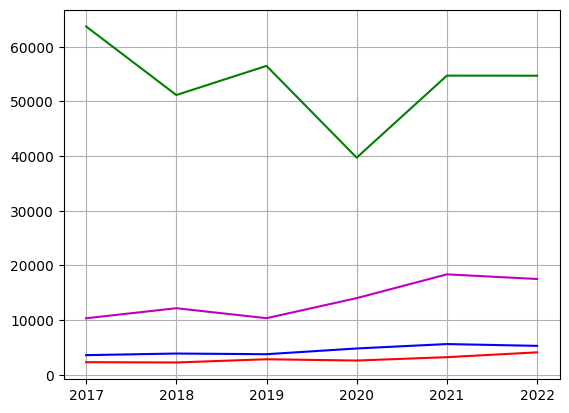

In [ ]:
plt.plot(y, x1, color='b')
plt.plot(y, x2, color='r')
plt.plot(y, x3, color='g')
plt.plot(y, x4, color='m')
plt.grid(True)
plt.show()

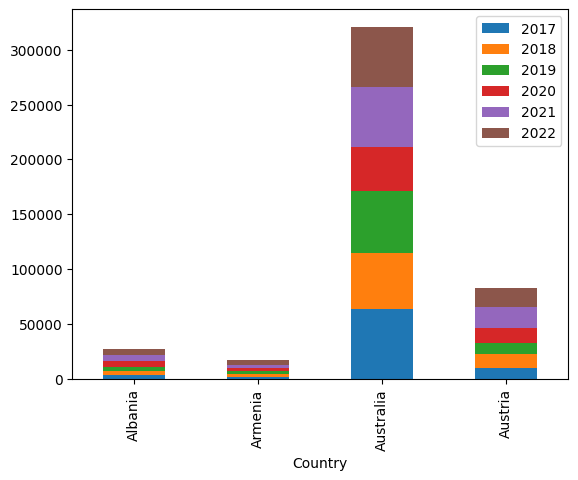

In [ ]:
dfc.plot(kind='bar', stacked=True, x='Country')
plt.show()

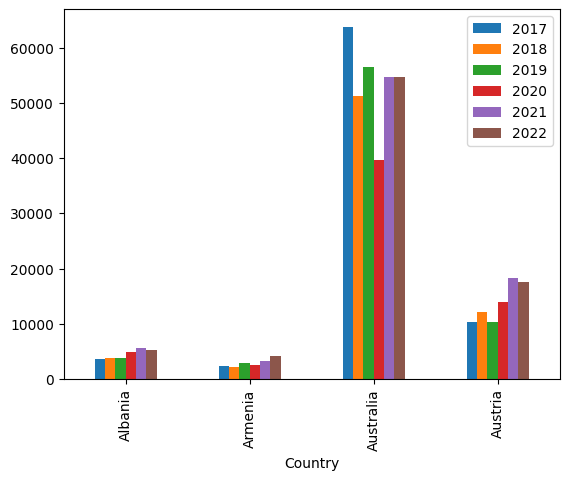

In [ ]:
dfc.plot(kind='bar' ,x='Country')
plt.show()

In [ ]:
df = pd.read_csv('dataset.csv')

In [ ]:
df.size

87175

In [ ]:
df.head(5)

,Country,Country Code,Series,Series Code,2017 [2017],2018 [2018],2019 [2019],2020 [2020],2021 [2021],2022 [2022],2023 [2023]
0,Advanced Economies,AME,"Core CPI,not seas.adj,,,",CORENS,..,..,..,..,..,..,..
1,Advanced Economies,AME,"Core CPI,seas.adj,,,",CORESA,110.52847664176,112.18222030299,113.90063041976,115.15263261251,117.52790127209,122.81797324635,128.06230178082
2,Advanced Economies,AME,"CPI Price, % y-o-y, median weighted, seas. adj.,",CPTOTSAXMZGY,1.4307988627,1.70266461276,1.43365554968,0.41258797832,2.44024851144,7.92080095034,4.69656049818
3,Advanced Economies,AME,"CPI Price, % y-o-y, not seas. adj.,,",CPTOTSAXNZGY,..,..,..,..,..,..,..
4,Advanced Economies,AME,"CPI Price, seas. adj.,,,",CPTOTSAXN,110.54244646312,112.64278124721,114.20450503305,115.00443642118,118.40454416373,126.6211606082,131.95982095567


In [ ]:
df.columns

Index(['Country', 'Country Code', 'Series', 'Series Code', '2017 [2017]',
       '2018 [2018]', '2019 [2019]', '2020 [2020]', '2021 [2021]',
       '2022 [2022]', '2023 [2023]'],
      dtype='object')

In [ ]:
print(df.dtypes)

Country         object
Country Code    object
Series          object
Series Code     object
2017 [2017]     object
2018 [2018]     object
2019 [2019]     object
2020 [2020]     object
2021 [2021]     object
2022 [2022]     object
2023 [2023]     object
dtype: object


In [ ]:
a = 2017
for x in ['2017 [2017]', '2018 [2018]','2019 [2019]','2020 [2020]','2021 [2021]','2022 [2022]','2023 [2023]']:
    df[x] = pd.to_numeric(df[x], errors='coerce')
    df = df.rename(columns={x: str(a)})
    a+=1

print(df)

                                                Country Country Code  \
0                                    Advanced Economies          AME   
1                                    Advanced Economies          AME   
2                                    Advanced Economies          AME   
3                                    Advanced Economies          AME   
4                                    Advanced Economies          AME   
...                                                 ...          ...   
7920                                                NaN          NaN   
7921                                                NaN          NaN   
7922                                                NaN          NaN   
7923  Data from database: Global Economic Monitor (GEM)          NaN   
7924                           Last Updated: 11/29/2023          NaN   

                                                Series   Series Code  \
0                             Core CPI,not seas.adj,,,        C

In [ ]:
df.head(3)

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022,2023
0,Advanced Economies,AME,"Core CPI,not seas.adj,,,",CORENS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Advanced Economies,AME,"Core CPI,seas.adj,,,",CORESA,110.528477,112.182220,113.900630,115.152633,117.527901,122.817973,128.062302
2,Advanced Economies,AME,"CPI Price, % y-o-y, median weighted, seas. adj.,",CPTOTSAXMZGY,1.430799,1.702665,1.433656,0.412588,2.440249,7.920801,4.696560


In [ ]:
df=df.dropna()
print(df)

                 Country Country Code  \
1     Advanced Economies          AME   
2     Advanced Economies          AME   
4     Advanced Economies          AME   
5     Advanced Economies          AME   
6     Advanced Economies          AME   
...                  ...          ...   
7855              Zambia          ZMB   
7876              Zambia          ZMB   
7890            Zimbabwe          ZWE   
7891            Zimbabwe          ZWE   
7912            Zimbabwe          ZWE   

                                                 Series   Series Code  \
1                                  Core CPI,seas.adj,,,        CORESA   
2      CPI Price, % y-o-y, median weighted, seas. adj.,  CPTOTSAXMZGY   
4                              CPI Price, seas. adj.,,,     CPTOTSAXN   
5                             CPI Price,not seas.adj,,,     CPTOTNSXN   
6     Exchange rate, new LCU per USD extended backwa...     DPANUSSPB   
...                                                 ...           ...

Рассмотрим уровень безработицы

In [ ]:
df[(df['Series'] == 'Unemployment rate,Percent,,,')].head(7)

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022,2023
359,Australia,AUS,"Unemployment rate,Percent,,,",UNEMPSA_,5.589567,5.298212,5.168316,6.491301,5.090124,3.695091,3.606861
395,Austria,AUT,"Unemployment rate,Percent,,,",UNEMPSA_,8.516309,7.712465,7.353367,9.997490,7.987052,6.294517,6.389846
1007,Bulgaria,BGR,"Unemployment rate,Percent,,,",UNEMPSA_,7.199167,6.175000,5.650833,7.359167,5.524167,4.497500,5.157778
1187,Canada,CAN,"Unemployment rate,Percent,,,",UNEMPSA_,6.408333,5.850000,5.700000,9.725000,7.508333,5.275000,5.280000
1367,Chile,CHL,"Unemployment rate,Percent,,,",UNEMPSA_,6.936574,7.339915,7.227479,10.539963,9.120701,7.813967,8.574271
1763,Croatia,HRV,"Unemployment rate,Percent,,,",UNEMPSA_,12.425000,9.858333,7.741667,9.008333,8.091667,6.800000,6.188889
2267,EMDE Europe and Central Asia,ECH,"Unemployment rate,Percent,,,",UNEMPSA_,6.853065,6.399104,6.764462,7.327738,6.603520,5.631646,5.079594


In [ ]:
b = ['Australia','Austria','Bulgaria','Canada','Chile']

dfc=df[(df['Series'] == 'Unemployment rate,Percent,,,') & (df['Country'].isin(b))]
dfc

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022,2023
359,Australia,AUS,"Unemployment rate,Percent,,,",UNEMPSA_,5.589567,5.298212,5.168316,6.491301,5.090124,3.695091,3.606861
395,Austria,AUT,"Unemployment rate,Percent,,,",UNEMPSA_,8.516309,7.712465,7.353367,9.997490,7.987052,6.294517,6.389846
1007,Bulgaria,BGR,"Unemployment rate,Percent,,,",UNEMPSA_,7.199167,6.175000,5.650833,7.359167,5.524167,4.497500,5.157778
1187,Canada,CAN,"Unemployment rate,Percent,,,",UNEMPSA_,6.408333,5.850000,5.700000,9.725000,7.508333,5.275000,5.280000
1367,Chile,CHL,"Unemployment rate,Percent,,,",UNEMPSA_,6.936574,7.339915,7.227479,10.539963,9.120701,7.813967,8.574271


In [ ]:
dfc.columns

Index(['Country', 'Country Code', 'Series', 'Series Code', '2017', '2018',
       '2019', '2020', '2021', '2022', '2023'],
      dtype='object')

In [ ]:
dfc = dfc[['Country', '2017', '2018', '2019', '2020', '2021', '2022', '2023']]
print(dfc)

        Country      2017      2018      2019       2020      2021      2022  \
359   Australia  5.589567  5.298212  5.168316   6.491301  5.090124  3.695091   
395     Austria  8.516309  7.712465  7.353367   9.997490  7.987052  6.294517   
1007   Bulgaria  7.199167  6.175000  5.650833   7.359167  5.524167  4.497500   
1187     Canada  6.408333  5.850000  5.700000   9.725000  7.508333  5.275000   
1367      Chile  6.936574  7.339915  7.227479  10.539963  9.120701  7.813967   

          2023  
359   3.606861  
395   6.389846  
1007  5.157778  
1187  5.280000  
1367  8.574271  


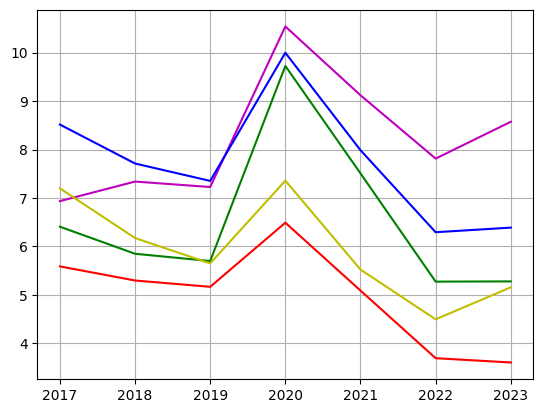

In [ ]:
x1=np.array(dfc[(dfc['Country'] == 'Chile')])[0,1:]
x2=np.array(dfc[(dfc['Country'] == 'Canada')])[0,1:]
x3=np.array(dfc[(dfc['Country'] == 'Australia')])[0,1:]
x4=np.array(dfc[(dfc['Country'] == 'Austria')])[0,1:]
x5=np.array(dfc[(dfc['Country'] == 'Bulgaria')])[0,1:]
y=[d for d in range(2017, 2024)]
plt.plot(y, x1, color='m')
plt.plot(y, x2, color='g')
plt.plot(y, x3, color='r')
plt.plot(y, x4, color='b')
plt.plot(y, x5, color='y')
plt.grid(True)
plt.show()

Рассмотрим Канаду

In [ ]:
dfc1 = df[(df['Country'] == 'Canada')]
dfc1

,Country,Country Code,Series,Series Code,2017,2018,2019,2020,2021,2022,2023
1152,Canada,CAN,"Core CPI,not seas.adj,,,",CORENS,1.124253e+02,1.145908e+02,1.169654e+02,1.182646e+02,1.210499e+02,1.270684e+02,1.314914e+02
1153,Canada,CAN,"Core CPI,seas.adj,,,",CORESA,1.119090e+02,1.140351e+02,1.164139e+02,1.177148e+02,1.205025e+02,1.265165e+02,1.308455e+02
1155,Canada,CAN,"CPI Price, % y-o-y, not seas. adj.,,",CPTOTSAXNZGY,1.609971e+00,2.274470e+00,1.936532e+00,7.108714e-01,3.407570e+00,6.808285e+00,3.435991e+00
1156,Canada,CAN,"CPI Price, seas. adj.,,,",CPTOTSAXN,1.126367e+02,1.151986e+02,1.174295e+02,1.182642e+02,1.222942e+02,1.306203e+02,1.351084e+02
1157,Canada,CAN,"CPI Price,not seas.adj,,,",CPTOTNSXN,1.133145e+02,1.158847e+02,1.181436e+02,1.189907e+02,1.230307e+02,1.314002e+02,1.360749e+02
1158,Canada,CAN,"Exchange rate, new LCU per USD extended backwa...",DPANUSSPB,1.298174e+00,1.296616e+00,1.327034e+00,1.341547e+00,1.253494e+00,1.301597e+00,1.350442e+00
1159,Canada,CAN,"Exchange rate, old LCU per USD extended forwar...",DPANUSSPF,1.298174e+00,1.296616e+00,1.327034e+00,1.341547e+00,1.253494e+00,1.301597e+00,1.350442e+00
1164,Canada,CAN,"Exports Merchandise, Customs, Price, US$, not ...",DXGSRMRCHNSXD,8.810148e-01,9.278466e-01,8.954463e-01,8.612081e-01,1.072463e+00,1.240631e+00,1.130959e+00
1165,Canada,CAN,"Exports Merchandise, Customs, Price, US$, seas...",DXGSRMRCHSAXD,8.799513e-01,9.267119e-01,8.945107e-01,8.603242e-01,1.071319e+00,1.239111e+00,1.128153e+00
1166,Canada,CAN,"GDP,constant 2010 LCU,millions,seas. adj.,",NYGDPMKTPSAKN,2.014933e+06,2.070888e+06,2.109991e+06,2.002923e+06,2.103305e+06,2.175616e+06,1.099762e+06


In [ ]:
dfc1 = dfc1[['Series', '2017', '2018', '2019', '2020', '2021', '2022', '2023']]
dfc1

,Series,2017,2018,2019,2020,2021,2022,2023
1152,"Core CPI,not seas.adj,,,",1.124253e+02,1.145908e+02,1.169654e+02,1.182646e+02,1.210499e+02,1.270684e+02,1.314914e+02
1153,"Core CPI,seas.adj,,,",1.119090e+02,1.140351e+02,1.164139e+02,1.177148e+02,1.205025e+02,1.265165e+02,1.308455e+02
1155,"CPI Price, % y-o-y, not seas. adj.,,",1.609971e+00,2.274470e+00,1.936532e+00,7.108714e-01,3.407570e+00,6.808285e+00,3.435991e+00
1156,"CPI Price, seas. adj.,,,",1.126367e+02,1.151986e+02,1.174295e+02,1.182642e+02,1.222942e+02,1.306203e+02,1.351084e+02
1157,"CPI Price,not seas.adj,,,",1.133145e+02,1.158847e+02,1.181436e+02,1.189907e+02,1.230307e+02,1.314002e+02,1.360749e+02
1158,"Exchange rate, new LCU per USD extended backwa...",1.298174e+00,1.296616e+00,1.327034e+00,1.341547e+00,1.253494e+00,1.301597e+00,1.350442e+00
1159,"Exchange rate, old LCU per USD extended forwar...",1.298174e+00,1.296616e+00,1.327034e+00,1.341547e+00,1.253494e+00,1.301597e+00,1.350442e+00
1164,"Exports Merchandise, Customs, Price, US$, not ...",8.810148e-01,9.278466e-01,8.954463e-01,8.612081e-01,1.072463e+00,1.240631e+00,1.130959e+00
1165,"Exports Merchandise, Customs, Price, US$, seas...",8.799513e-01,9.267119e-01,8.945107e-01,8.603242e-01,1.071319e+00,1.239111e+00,1.128153e+00
1166,"GDP,constant 2010 LCU,millions,seas. adj.,",2.014933e+06,2.070888e+06,2.109991e+06,2.002923e+06,2.103305e+06,2.175616e+06,1.099762e+06


In [ ]:
dfc1.size

168

Рассмотрим зависимость безработицы и индекса потребительских цен и построим модель для прогноза

In [ ]:
df = dfc1.drop(dfc1.index[:1])
df = df.drop(df.index[2:20])
df

,Series,2017,2018,2019,2020,2021,2022,2023
1153,"Core CPI,seas.adj,,,",111.909010,114.035088,116.413916,117.714838,120.502528,126.516503,130.845475
1155,"CPI Price, % y-o-y, not seas. adj.,,",1.609971,2.274470,1.936532,0.710871,3.407570,6.808285,3.435991


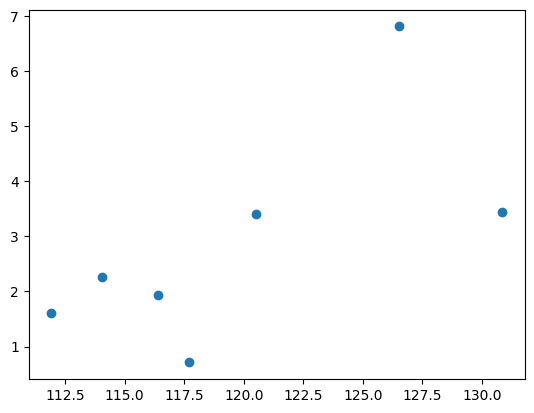

In [ ]:
# X - факторная переменная: индекс потребительских цен
# y - результирующая: уровень безработицы, %
X = np.array([111.91, 114.04, 116.41, 117.71, 120.50, 126.52, 130.85])[:, np.newaxis]
y = np.array([1.61, 2.27, 1.94, 0.71, 3.41, 6.81, 3.44])
plt.scatter(X, y)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
pr = LinearRegression()
quadratic = PolynomialFeatures(degree=15)
X_quad = quadratic.fit_transform(X)
pr.fit(X_quad, y)
X_quad

array([[1.00000000e+00, 1.11910000e+02, 1.25238481e+04, 1.40154384e+06,
        1.56846771e+08, 1.75527222e+10, 1.96432514e+12, 2.19827626e+14,
        2.46009096e+16, 2.75308780e+18, 3.08098056e+20, 3.44792534e+22,
        3.85857325e+24, 4.31812932e+26, 4.83241852e+28, 5.40795957e+30],
       [1.00000000e+00, 1.14040000e+02, 1.30051216e+04, 1.48310407e+06,
        1.69133188e+08, 1.92879487e+10, 2.19959767e+12, 2.50842119e+14,
        2.86060352e+16, 3.26223226e+18, 3.72024967e+20, 4.24257272e+22,
        4.83822993e+24, 5.51751741e+26, 6.29217686e+28, 7.17559849e+30],
       [1.00000000e+00, 1.16410000e+02, 1.35512881e+04, 1.57750545e+06,
        1.83637409e+08, 2.13772308e+10, 2.48852344e+12, 2.89689013e+14,
        3.37226980e+16, 3.92565928e+18, 4.56985997e+20, 5.31977399e+22,
        6.19274890e+24, 7.20897899e+26, 8.39197245e+28, 9.76909513e+30],
       [1.00000000e+00, 1.17710000e+02, 1.38556441e+04, 1.63094787e+06,
        1.91978873e+08, 2.25978332e+10, 2.65999094e+12, 3.131

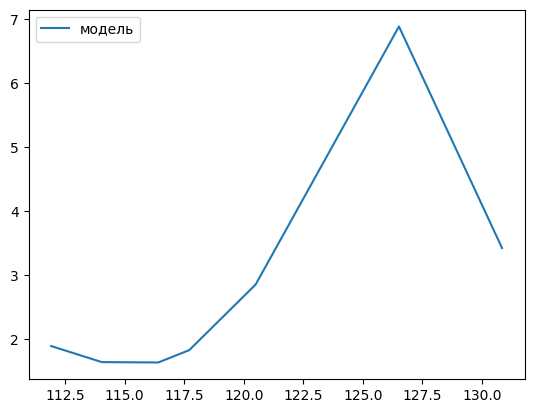

MSE 0.30469483185425555
Коэффициент детерминации: 0.91


In [ ]:
y_pr = pr.predict(X_quad)

from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
plt.plot(X, y_pr, label = 'модель')
plt.legend(loc='upper left')
plt.show()
y_pred1 = pr.predict(X_quad)
print('MSE', mean_squared_error(y, y_pred1))
r2p = r2_score(y, y_pred1)
print(f"Коэффициент детерминации: {r2p:.2f}")

In [ ]:
print(dfc1['Series'].unique())

['Core CPI,not seas.adj,,,' 'Core CPI,seas.adj,,,'
 'CPI Price, % y-o-y, not seas. adj.,,' 'CPI Price, seas. adj.,,,'
 'CPI Price,not seas.adj,,,'
 'Exchange rate, new LCU per USD extended backward, period average,,'
 'Exchange rate, old LCU per USD extended forward, period average,,'
 'Exports Merchandise, Customs, Price, US$, not seas. adj.'
 'Exports Merchandise, Customs, Price, US$, seas. adj.'
 'GDP,constant 2010 LCU,millions,seas. adj.,'
 'GDP,constant 2010 US$,millions,seas. adj.,'
 'GDP,current LCU,millions,seas. adj.,'
 'GDP,current US$,millions,seas. adj.,'
 'Imports Merchandise, Customs, Price, US$, not seas. adj.'
 'Imports Merchandise, Customs, Price, US$, seas. adj.'
 'Nominal Effective Exchange Rate,,,,'
 'Official exchange rate, LCU per USD, period average,,'
 'Real Effective Exchange Rate,,,,' 'Stock Markets, LCU,,,'
 'Stock Markets, US$,,,' 'Unemployment rate,Percent,,,']


In [ ]:
dfc1 = dfc1.transpose()
dfc1

,1152,1153,1155,1156,1157,1158,1159,1164,1165,1166,1167,1168,1169,1174,1175,1179,1180,1181,1183,1184,1187
Series,"Core CPI,not seas.adj,,,","Core CPI,seas.adj,,,","CPI Price, % y-o-y, not seas. adj.,,","CPI Price, seas. adj.,,,","CPI Price,not seas.adj,,,","Exchange rate, new LCU per USD extended backwa...","Exchange rate, old LCU per USD extended forwar...","Exports Merchandise, Customs, Price, US$, not ...","Exports Merchandise, Customs, Price, US$, seas...","GDP,constant 2010 LCU,millions,seas. adj.,","GDP,constant 2010 US$,millions,seas. adj.,","GDP,current LCU,millions,seas. adj.,","GDP,current US$,millions,seas. adj.,","Imports Merchandise, Customs, Price, US$, not ...","Imports Merchandise, Customs, Price, US$, seas...","Nominal Effective Exchange Rate,,,,","Official exchange rate, LCU per USD, period av...","Real Effective Exchange Rate,,,,","Stock Markets, LCU,,,","Stock Markets, US$,,,","Unemployment rate,Percent,,,"
2017,112.425329,111.90901,1.609971,112.63673,113.314509,1.298174,1.298174,0.881015,0.879951,2014932.75,1846716.419283,2140641.0,1650650.960907,0.981659,0.981671,84.608788,1.298174,83.554899,133.411293,107.289222,6.408333
2018,114.5908,114.035088,2.27447,115.198618,115.884738,1.296616,1.296616,0.927847,0.926712,2070888.25,1898000.483528,2235675.0,1724515.312653,1.013508,1.013571,84.228881,1.296616,82.947933,135.010545,108.68252,5.85
2019,116.965352,116.413916,1.936532,117.429476,118.143643,1.327034,1.327034,0.895446,0.894511,2109991.25,1933838.975975,2313563.0,1743521.102169,1.015347,1.015286,83.777191,1.327034,82.400189,140.050828,110.088207,5.7
2020,118.264636,117.714838,0.710871,118.264249,118.990733,1.341547,1.341547,0.861208,0.860324,2002922.75,1835709.072167,2209681.0,1649798.265711,1.014122,1.013993,83.617388,1.341547,81.572537,137.567988,107.275351,9.725
2021,121.049881,120.502528,3.40757,122.294185,123.030698,1.253494,1.253494,1.072463,1.071319,2103305.25,1927711.155591,2509618.0,2002243.238325,1.127705,1.127646,87.634704,1.253494,85.418449,169.990208,141.472178,7.508333
2022,127.068399,126.516503,6.808285,130.620322,131.400232,1.301597,1.301597,1.240631,1.239111,2175616.5,1993985.512724,2782645.0,2139184.110303,1.233106,1.233248,87.955057,1.301597,85.408409,173.125519,138.984518,5.275
2023,131.491438,130.845475,3.435991,135.108424,136.074911,1.350442,1.350442,1.130959,1.128153,1099762.0,1007948.549501,1408043.0,1044864.442856,1.23115,1.233277,85.17514,1.350442,82.391877,172.051769,132.914056,5.28


In [ ]:
dfс1 = pd.DataFrame(columns = ['Series'])
dfc1

,1152,1153,1155,1156,1157,1158,1159,1164,1165,1166,1167,1168,1169,1174,1175,1179,1180,1181,1183,1184,1187
Series,"Core CPI,not seas.adj,,,","Core CPI,seas.adj,,,","CPI Price, % y-o-y, not seas. adj.,,","CPI Price, seas. adj.,,,","CPI Price,not seas.adj,,,","Exchange rate, new LCU per USD extended backwa...","Exchange rate, old LCU per USD extended forwar...","Exports Merchandise, Customs, Price, US$, not ...","Exports Merchandise, Customs, Price, US$, seas...","GDP,constant 2010 LCU,millions,seas. adj.,","GDP,constant 2010 US$,millions,seas. adj.,","GDP,current LCU,millions,seas. adj.,","GDP,current US$,millions,seas. adj.,","Imports Merchandise, Customs, Price, US$, not ...","Imports Merchandise, Customs, Price, US$, seas...","Nominal Effective Exchange Rate,,,,","Official exchange rate, LCU per USD, period av...","Real Effective Exchange Rate,,,,","Stock Markets, LCU,,,","Stock Markets, US$,,,","Unemployment rate,Percent,,,"
2017,112.425329,111.90901,1.609971,112.63673,113.314509,1.298174,1.298174,0.881015,0.879951,2014932.75,1846716.419283,2140641.0,1650650.960907,0.981659,0.981671,84.608788,1.298174,83.554899,133.411293,107.289222,6.408333
2018,114.5908,114.035088,2.27447,115.198618,115.884738,1.296616,1.296616,0.927847,0.926712,2070888.25,1898000.483528,2235675.0,1724515.312653,1.013508,1.013571,84.228881,1.296616,82.947933,135.010545,108.68252,5.85
2019,116.965352,116.413916,1.936532,117.429476,118.143643,1.327034,1.327034,0.895446,0.894511,2109991.25,1933838.975975,2313563.0,1743521.102169,1.015347,1.015286,83.777191,1.327034,82.400189,140.050828,110.088207,5.7
2020,118.264636,117.714838,0.710871,118.264249,118.990733,1.341547,1.341547,0.861208,0.860324,2002922.75,1835709.072167,2209681.0,1649798.265711,1.014122,1.013993,83.617388,1.341547,81.572537,137.567988,107.275351,9.725
2021,121.049881,120.502528,3.40757,122.294185,123.030698,1.253494,1.253494,1.072463,1.071319,2103305.25,1927711.155591,2509618.0,2002243.238325,1.127705,1.127646,87.634704,1.253494,85.418449,169.990208,141.472178,7.508333
2022,127.068399,126.516503,6.808285,130.620322,131.400232,1.301597,1.301597,1.240631,1.239111,2175616.5,1993985.512724,2782645.0,2139184.110303,1.233106,1.233248,87.955057,1.301597,85.408409,173.125519,138.984518,5.275
2023,131.491438,130.845475,3.435991,135.108424,136.074911,1.350442,1.350442,1.130959,1.128153,1099762.0,1007948.549501,1408043.0,1044864.442856,1.23115,1.233277,85.17514,1.350442,82.391877,172.051769,132.914056,5.28


In [ ]:
dfc1.dtypes

,0
1152,object
1153,object
1155,object
1156,object
1157,object
1158,object
1159,object
1164,object
1165,object
1166,object


In [ ]:
for x in ['1152','1153','1155','1156','1157','1158','1159','1164','1165','1166','1167','1168','1169','1174','1175','1179','1180','1181','1183','1184','1187']:
    if x in dfс1.columns:
        dfс1 = dfс1.rename(columns={x: str(x)})

In [ ]:
dfc1 = dfc1.drop(dfc1.index[:1])
dfc1

,1152,1153,1155,1156,1157,1158,1159,1164,1165,1166,1167,1168,1169,1174,1175,1179,1180,1181,1183,1184,1187
2018,114.5908,114.035088,2.27447,115.198618,115.884738,1.296616,1.296616,0.927847,0.926712,2070888.25,1898000.483528,2235675.0,1724515.312653,1.013508,1.013571,84.228881,1.296616,82.947933,135.010545,108.68252,5.85
2019,116.965352,116.413916,1.936532,117.429476,118.143643,1.327034,1.327034,0.895446,0.894511,2109991.25,1933838.975975,2313563.0,1743521.102169,1.015347,1.015286,83.777191,1.327034,82.400189,140.050828,110.088207,5.7
2020,118.264636,117.714838,0.710871,118.264249,118.990733,1.341547,1.341547,0.861208,0.860324,2002922.75,1835709.072167,2209681.0,1649798.265711,1.014122,1.013993,83.617388,1.341547,81.572537,137.567988,107.275351,9.725
2021,121.049881,120.502528,3.40757,122.294185,123.030698,1.253494,1.253494,1.072463,1.071319,2103305.25,1927711.155591,2509618.0,2002243.238325,1.127705,1.127646,87.634704,1.253494,85.418449,169.990208,141.472178,7.508333
2022,127.068399,126.516503,6.808285,130.620322,131.400232,1.301597,1.301597,1.240631,1.239111,2175616.5,1993985.512724,2782645.0,2139184.110303,1.233106,1.233248,87.955057,1.301597,85.408409,173.125519,138.984518,5.275
2023,131.491438,130.845475,3.435991,135.108424,136.074911,1.350442,1.350442,1.130959,1.128153,1099762.0,1007948.549501,1408043.0,1044864.442856,1.23115,1.233277,85.17514,1.350442,82.391877,172.051769,132.914056,5.28


# Корреляция

In [ ]:
cor_mat=dfc1.corr()

<Axes: >

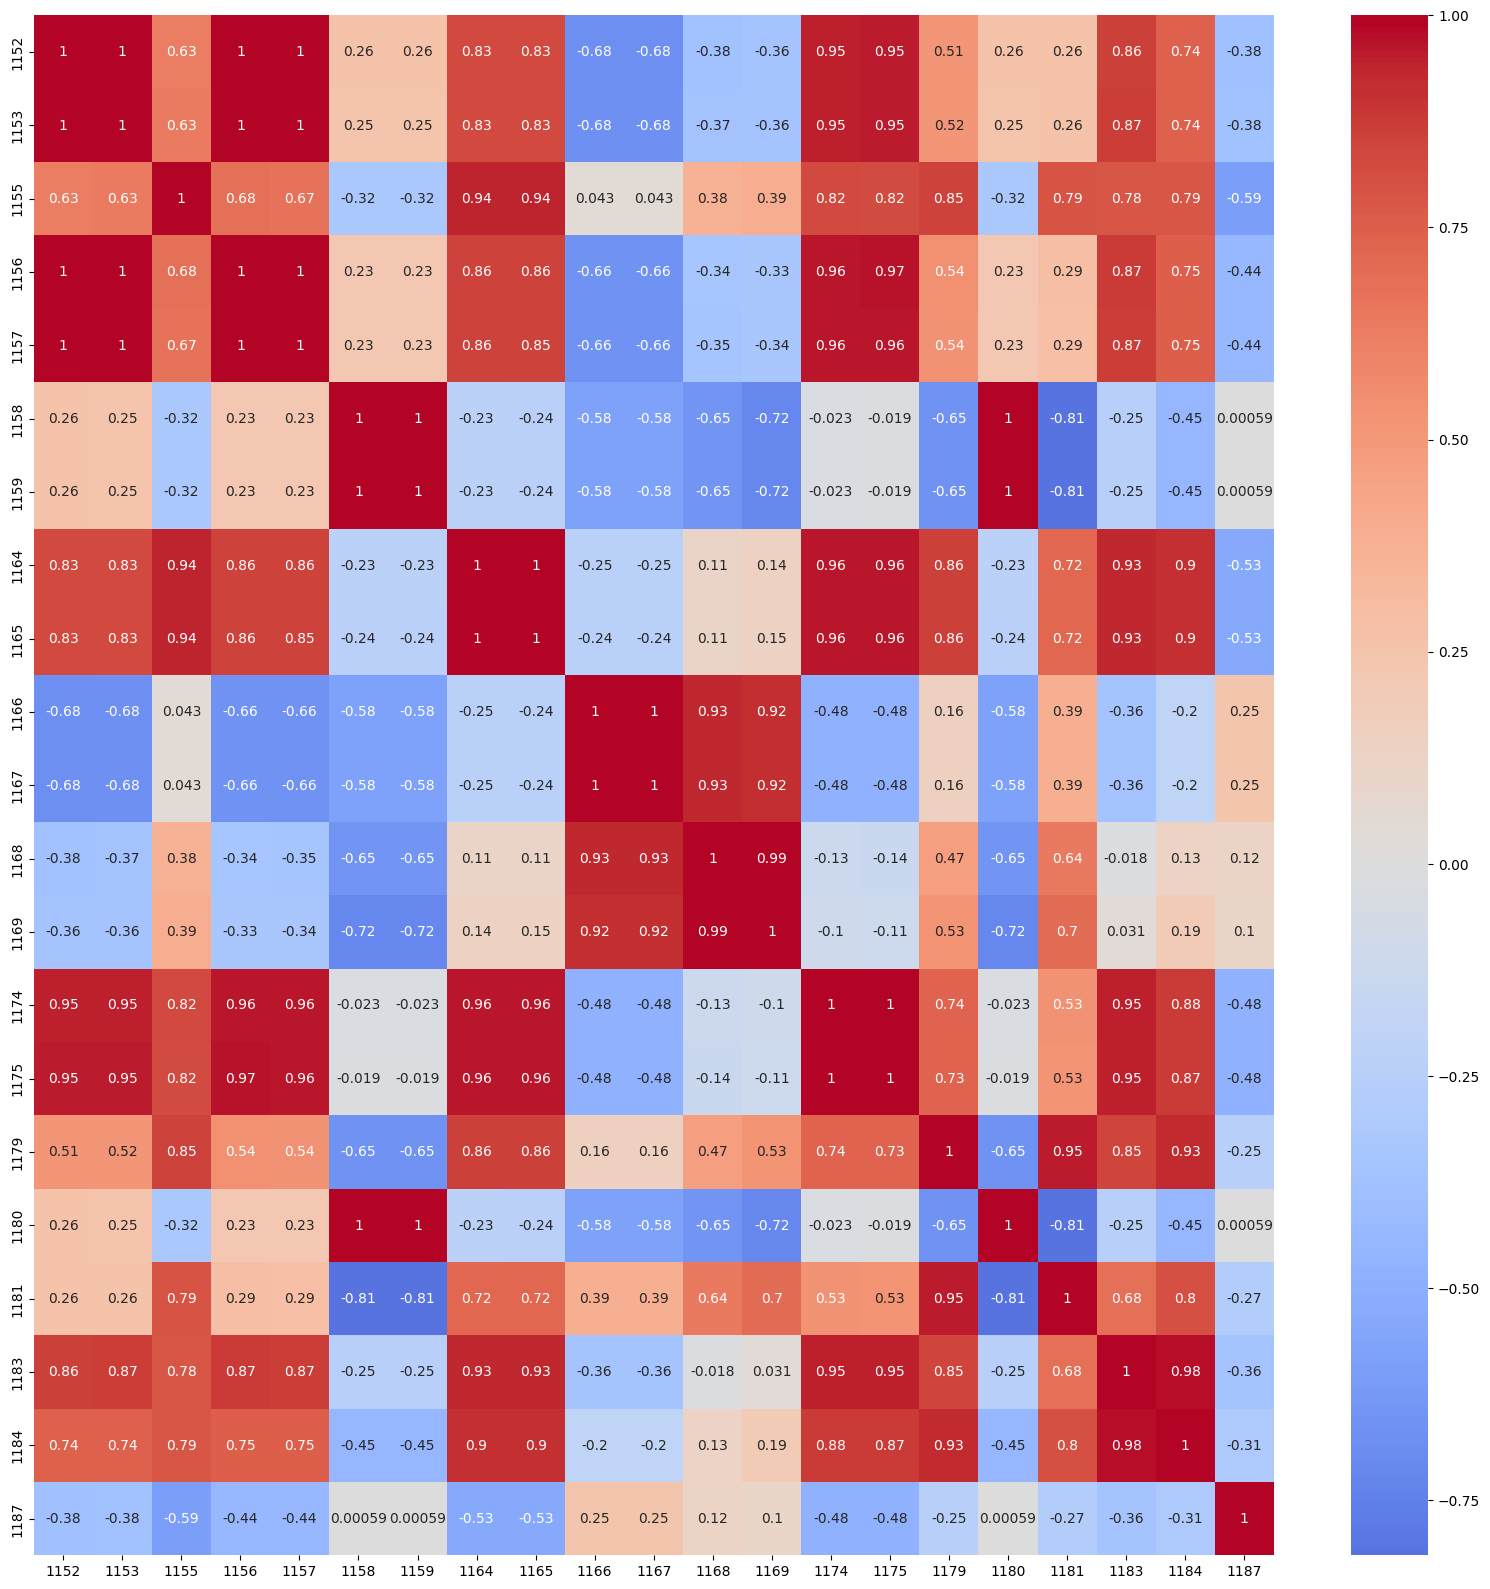

In [ ]:
plt.figure(figsize=(20, 20))
sns.heatmap(cor_mat, annot=True, cmap='coolwarm', center=0)

In [ ]:
dfc1.columns

Index([1152, 1153, 1155, 1156, 1157, 1158, 1159, 1164, 1165, 1166, 1167, 1168,
       1169, 1174, 1175, 1179, 1180, 1181, 1183, 1184, 1187],
      dtype='int64')

In [ ]:
dfc1=dfc1[[1153,1155,1159,1165,1167,1169,1175,1181,1184,1187]]
dfc1

,1153,1155,1159,1165,1167,1169,1175,1181,1184,1187
2018,114.035088,2.27447,1.296616,0.926712,1898000.483528,1724515.312653,1.013571,82.947933,108.68252,5.85
2019,116.413916,1.936532,1.327034,0.894511,1933838.975975,1743521.102169,1.015286,82.400189,110.088207,5.7
2020,117.714838,0.710871,1.341547,0.860324,1835709.072167,1649798.265711,1.013993,81.572537,107.275351,9.725
2021,120.502528,3.40757,1.253494,1.071319,1927711.155591,2002243.238325,1.127646,85.418449,141.472178,7.508333
2022,126.516503,6.808285,1.301597,1.239111,1993985.512724,2139184.110303,1.233248,85.408409,138.984518,5.275
2023,130.845475,3.435991,1.350442,1.128153,1007948.549501,1044864.442856,1.233277,82.391877,132.914056,5.28


<Axes: >

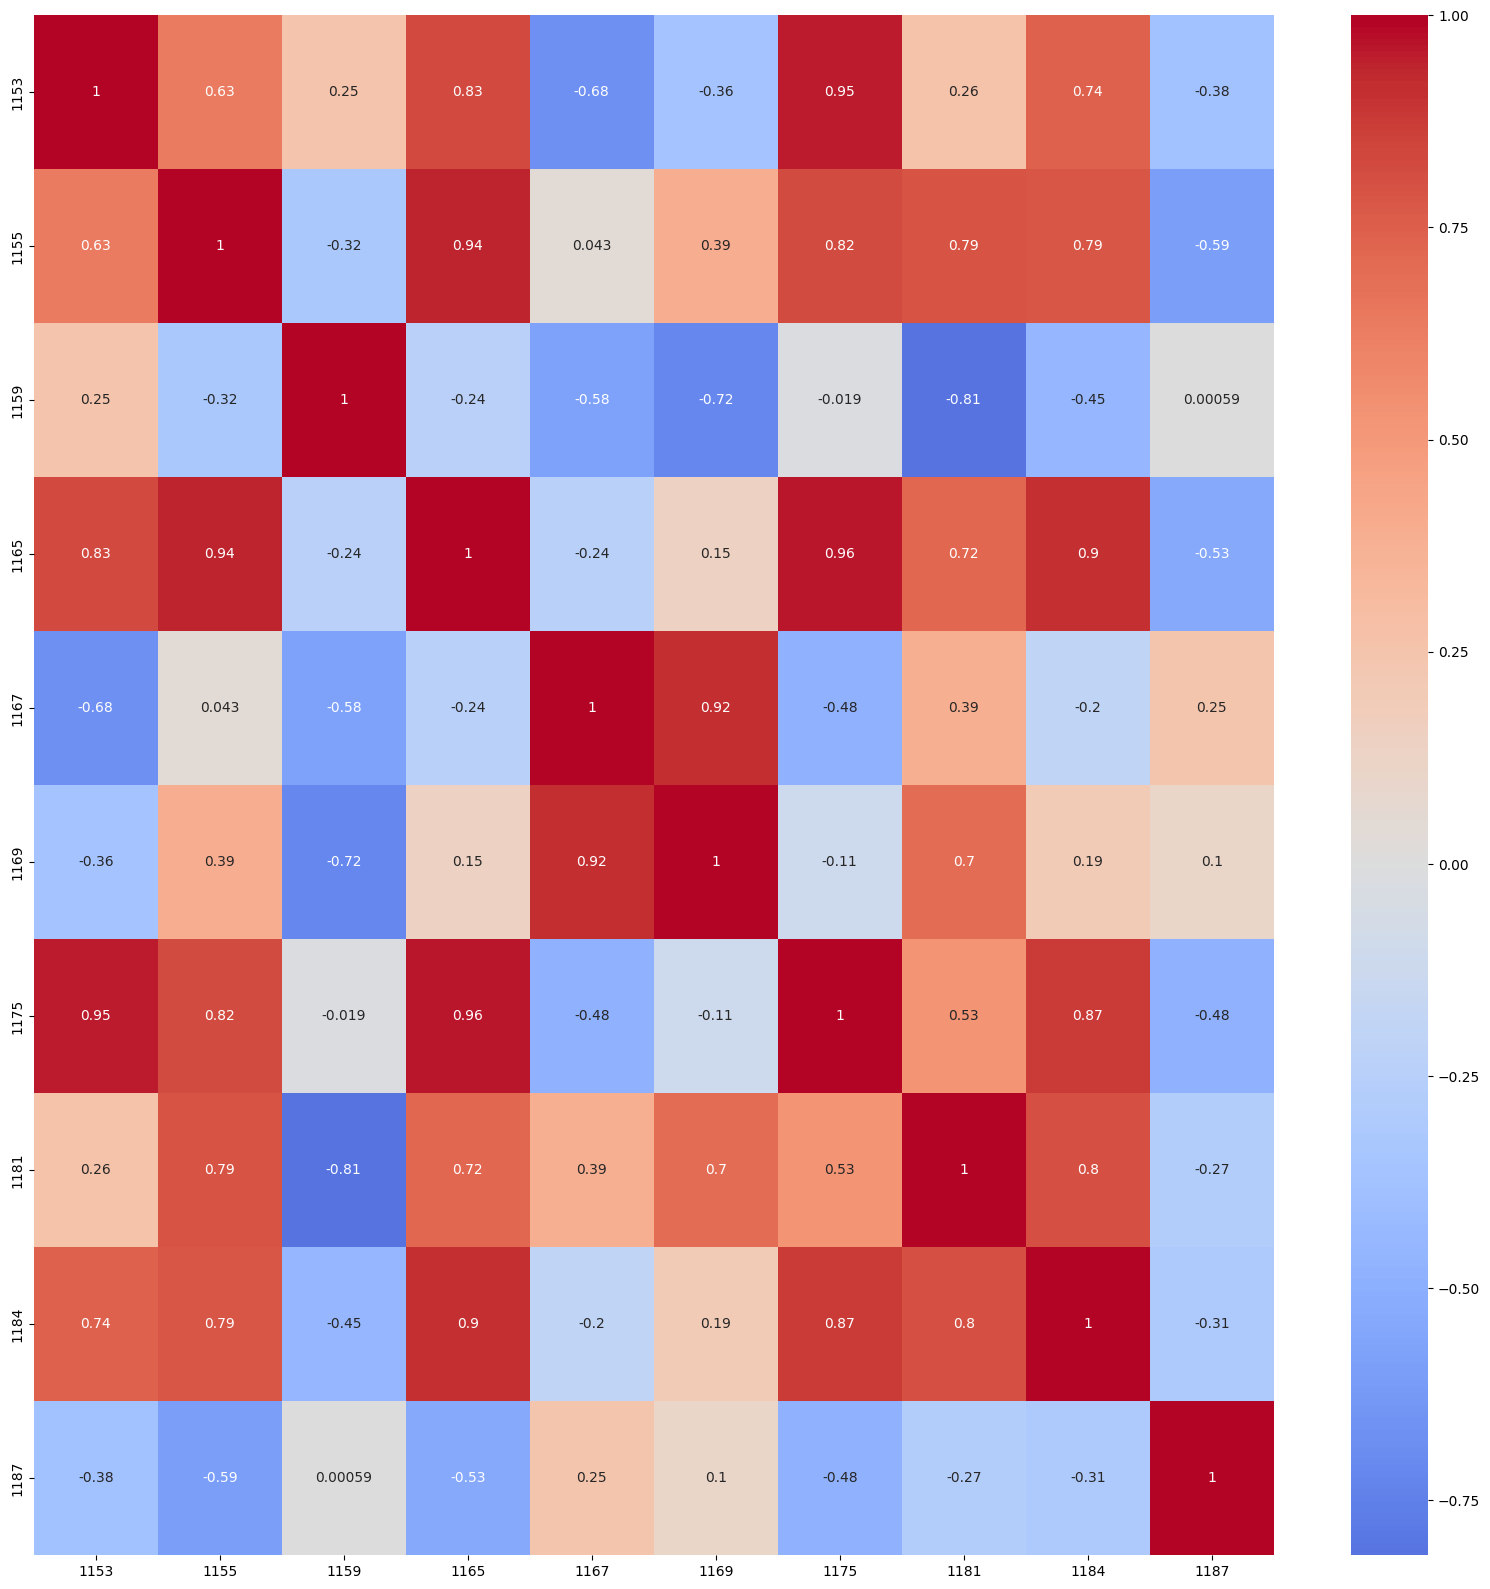

In [ ]:
cor_mat=dfc1.corr()
plt.figure(figsize=(20, 20))
sns.heatmap(cor_mat, annot=True, cmap='coolwarm', center=0)

Далее возьмем только уровень безработицы (1187) и средний уровеь инфлции (1155)

In [ ]:
df2 = dfc1[[1155,1187]]
df2

,1155,1187
2018,2.27447,5.85
2019,1.936532,5.7
2020,0.710871,9.725
2021,3.40757,7.508333
2022,6.808285,5.275
2023,3.435991,5.28


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df2)

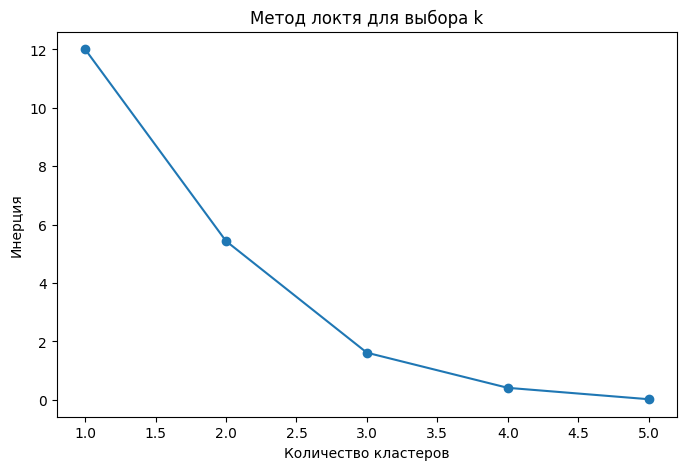

In [ ]:
inertia = []
k_values = range(1, 6)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o', linestyle='-')
plt.xlabel('Количество кластеров')
plt.ylabel('Инерция')
plt.title('Метод локтя для выбора k')
plt.show()

<ipython-input-193-dae638762bd2>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Cluster'] = clusters


Text(0, 0.5, '1187')

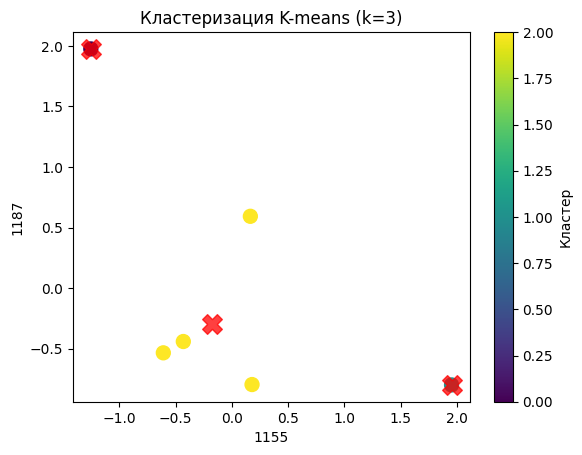

In [ ]:
import seaborn as sns
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(data_scaled)
df2['Cluster'] = clusters

scatter = plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=clusters, cmap='viridis', s=100)
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X')
plt.colorbar(scatter, label='Кластер')
plt.title(f'Кластеризация K-means (k=3)')
plt.xlabel('1155')
plt.ylabel('1187')

Вывод по практической части: При сравнении общих резервов таких стран, как Австралия, Австрия, Армения и Албании видно, что значение данного показателя в Австралии в несколько раз превышает значения в трех других странах, однако больше и вариация данного признака. Сравнение уровня безработицы в Австралии, Чили, Канаде, Австрии и Болгарии показало, что во всех странах наблюдался резкий рост данного показателя в период с 2019 года, который достиг пика в последующем 2020 году и начал снижаться. Это можно объяснить пандемией COVID-19, которая вызвала ряд сокращений рабочих мест во многих компаниях и крупные нарушения национальных экономик в целом. Далее был рассмотрен уровень безработицы и построена модель полиномиальной регрессии, описывающей зависимость уровня безработицы в стране от индекса потребительских цен, а также позволяющей строить соответствующие прогнозы. Также были построены две корреляционные матрицы - первая содержала все известные факторы, другая исключала те факторные переменные, которые имели высокую мультиколлинеарность (коэффициент корреляции = 1) и произведена кластеризация методом k-means по двум переменным - средний уровень инфляции и уровень безработицы.